In [1]:
import json
import glob
import matplotlib.pyplot as plt
import numpy as np

from pathlib import Path

In [12]:
def get_ppo_log_files():
    base_dir = Path("../../../results\\methods\\Hyperparams_controller\\ppo_logs")
    return sorted(glob.glob(str(base_dir / "*.json")))

# Action distribution

In [10]:
def plot_action_distribution(log_path):
    with open(log_path, "r") as f:
        logs = json.load(f)

    actions = [x["action"] for x in logs]

    counts = np.bincount(actions, minlength=8)

    plt.figure(figsize=(8, 4))
    plt.bar(range(len(counts)), counts)
    plt.xlabel("Action")
    plt.ylabel("Frequency")
    plt.title("PPO Action Distribution")
    plt.xticks(range(8))
    plt.show()

Found 36 JSON files: ['..\\..\\..\\results\\methods\\Hyperparams_controller\\ppo_logs\\C102_50_5.json', '..\\..\\..\\results\\methods\\Hyperparams_controller\\ppo_logs\\C103_100_10.json', '..\\..\\..\\results\\methods\\Hyperparams_controller\\ppo_logs\\C104_100_10.json', '..\\..\\..\\results\\methods\\Hyperparams_controller\\ppo_logs\\C105_50_5.json', '..\\..\\..\\results\\methods\\Hyperparams_controller\\ppo_logs\\C107_100_10.json', '..\\..\\..\\results\\methods\\Hyperparams_controller\\ppo_logs\\C109_50_5.json', '..\\..\\..\\results\\methods\\Hyperparams_controller\\ppo_logs\\C201_50_5.json', '..\\..\\..\\results\\methods\\Hyperparams_controller\\ppo_logs\\C202_100_10.json', '..\\..\\..\\results\\methods\\Hyperparams_controller\\ppo_logs\\C204_50_5.json', '..\\..\\..\\results\\methods\\Hyperparams_controller\\ppo_logs\\C206_100_10.json', '..\\..\\..\\results\\methods\\Hyperparams_controller\\ppo_logs\\C207_50_5.json', '..\\..\\..\\results\\methods\\Hyperparams_controller\\ppo_logs\\C

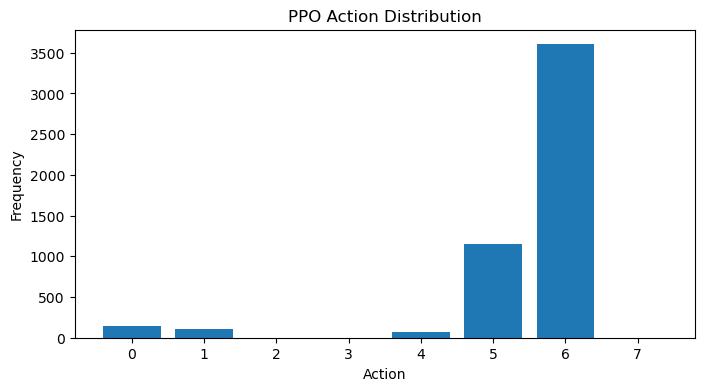

Plotting distribution for: ..\..\..\results\methods\Hyperparams_controller\ppo_logs\C103_100_10.json


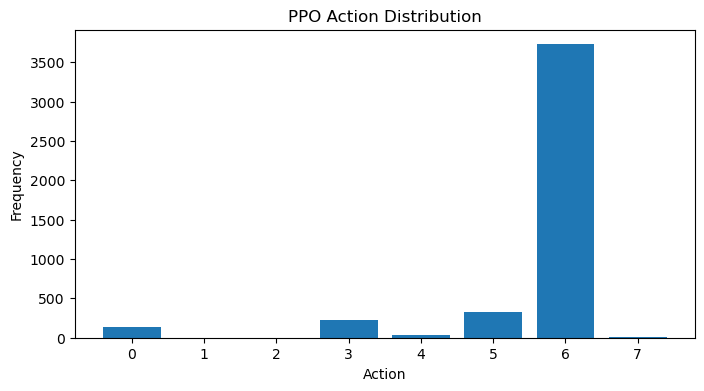

Plotting distribution for: ..\..\..\results\methods\Hyperparams_controller\ppo_logs\C104_100_10.json


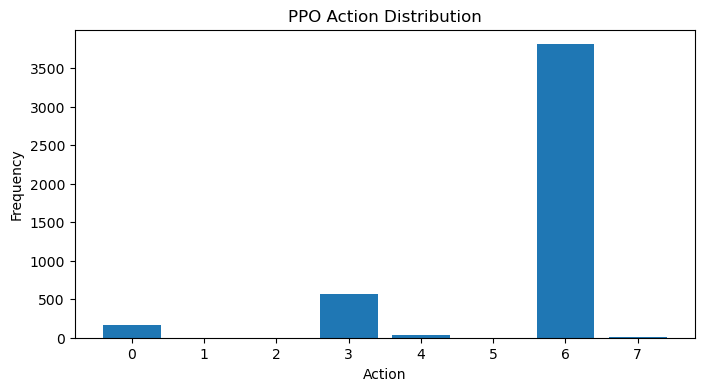

Plotting distribution for: ..\..\..\results\methods\Hyperparams_controller\ppo_logs\C105_50_5.json


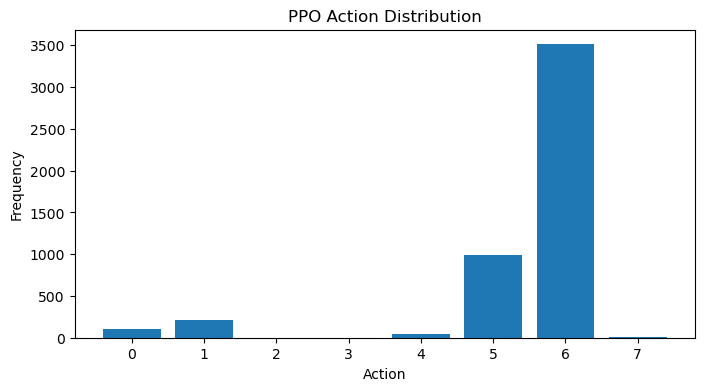

Plotting distribution for: ..\..\..\results\methods\Hyperparams_controller\ppo_logs\C107_100_10.json


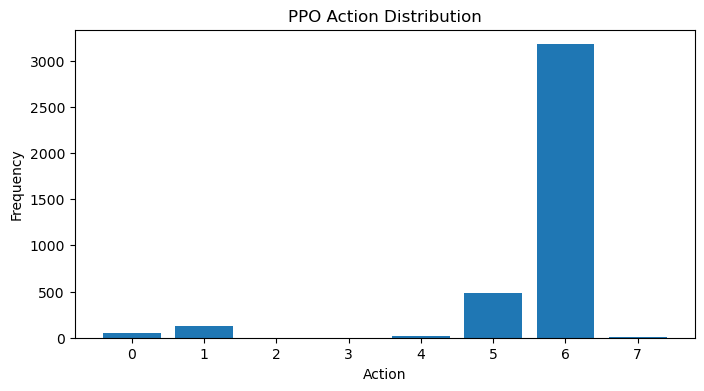

Plotting distribution for: ..\..\..\results\methods\Hyperparams_controller\ppo_logs\C109_50_5.json


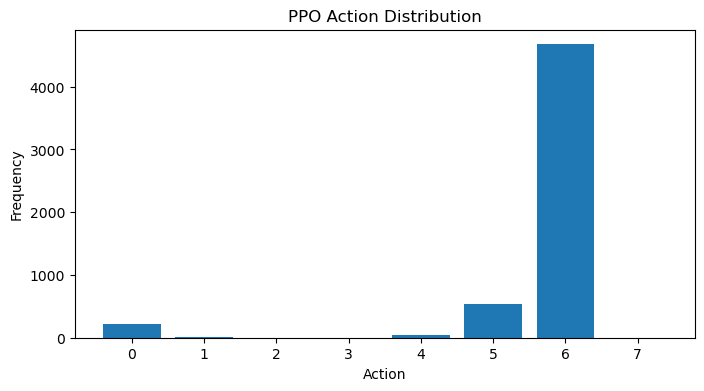

Plotting distribution for: ..\..\..\results\methods\Hyperparams_controller\ppo_logs\C201_50_5.json


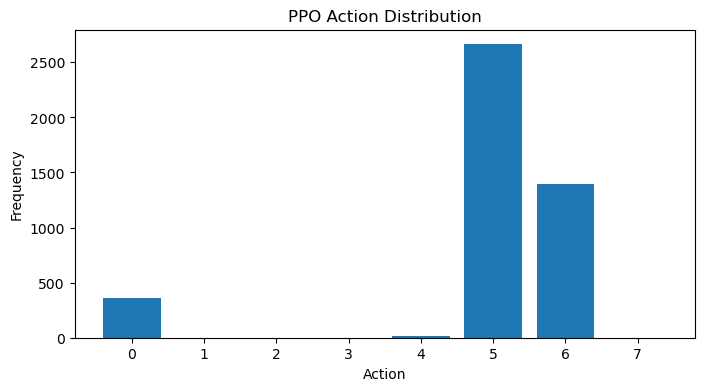

Plotting distribution for: ..\..\..\results\methods\Hyperparams_controller\ppo_logs\C202_100_10.json


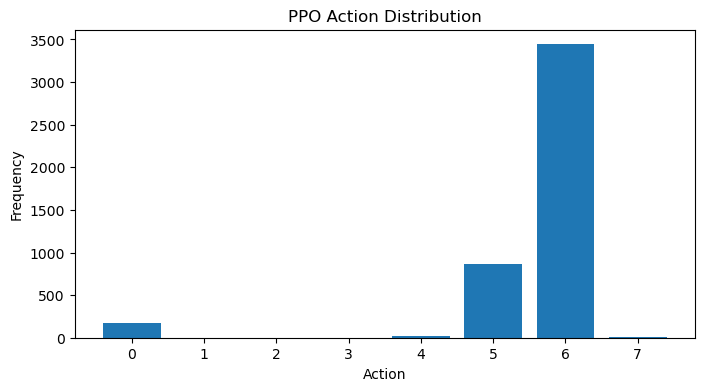

Plotting distribution for: ..\..\..\results\methods\Hyperparams_controller\ppo_logs\C204_50_5.json


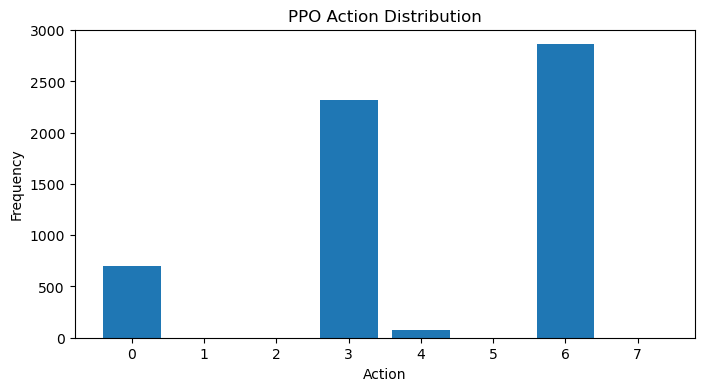

Plotting distribution for: ..\..\..\results\methods\Hyperparams_controller\ppo_logs\C206_100_10.json


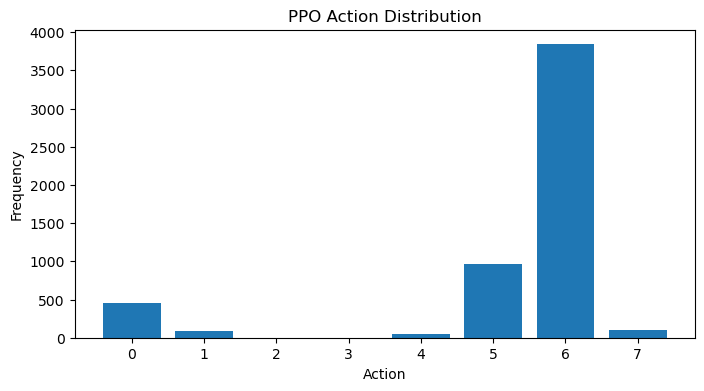

Plotting distribution for: ..\..\..\results\methods\Hyperparams_controller\ppo_logs\C207_50_5.json


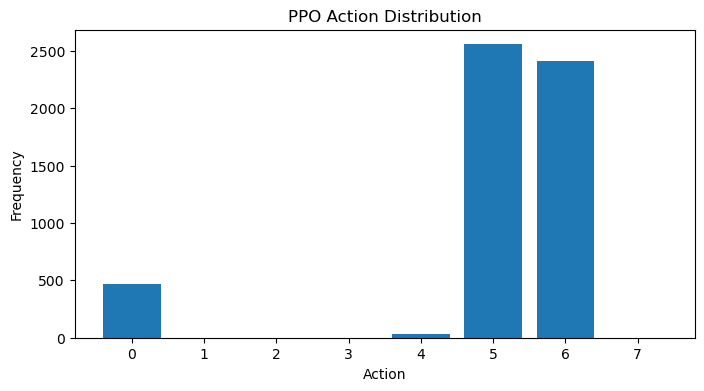

Plotting distribution for: ..\..\..\results\methods\Hyperparams_controller\ppo_logs\C208_100_10.json


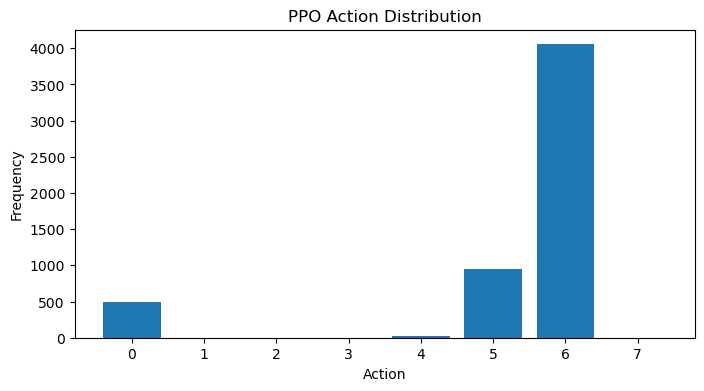

Plotting distribution for: ..\..\..\results\methods\Hyperparams_controller\ppo_logs\R101_100_10.json


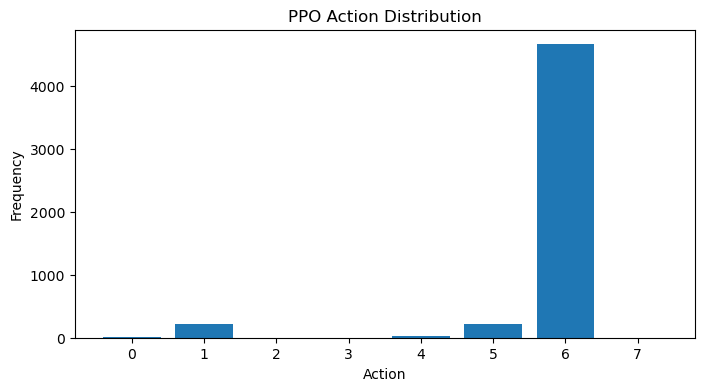

Plotting distribution for: ..\..\..\results\methods\Hyperparams_controller\ppo_logs\R102_50_5.json


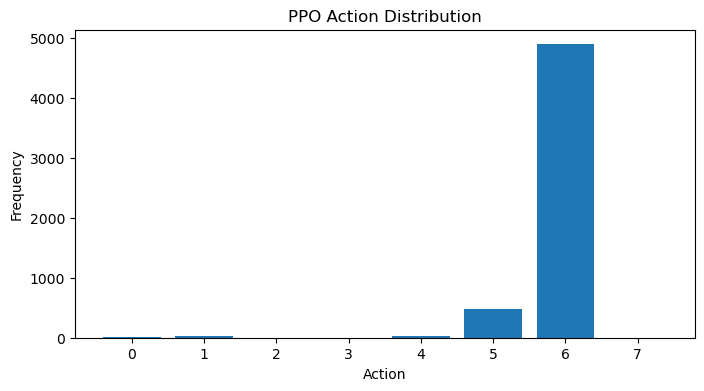

Plotting distribution for: ..\..\..\results\methods\Hyperparams_controller\ppo_logs\R105_100_10.json


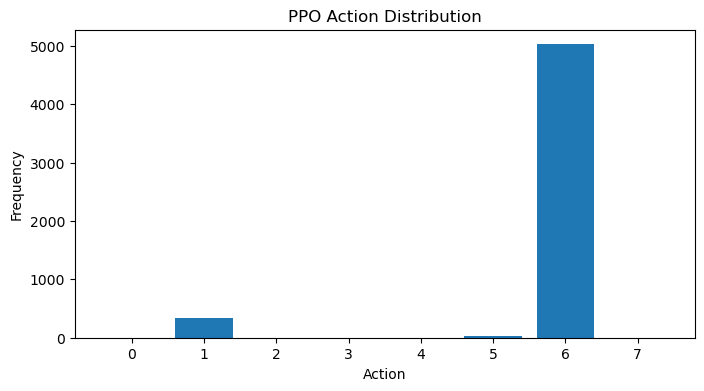

Plotting distribution for: ..\..\..\results\methods\Hyperparams_controller\ppo_logs\R106_50_5.json


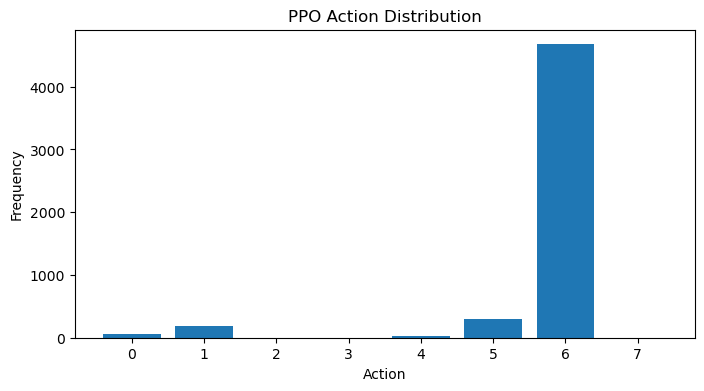

Plotting distribution for: ..\..\..\results\methods\Hyperparams_controller\ppo_logs\R110_50_5.json


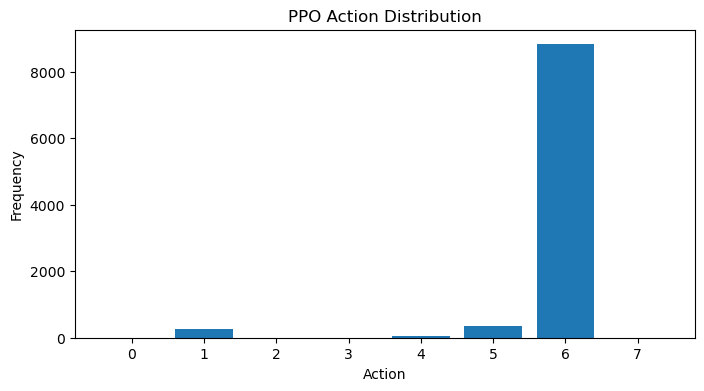

Plotting distribution for: ..\..\..\results\methods\Hyperparams_controller\ppo_logs\R111_100_10.json


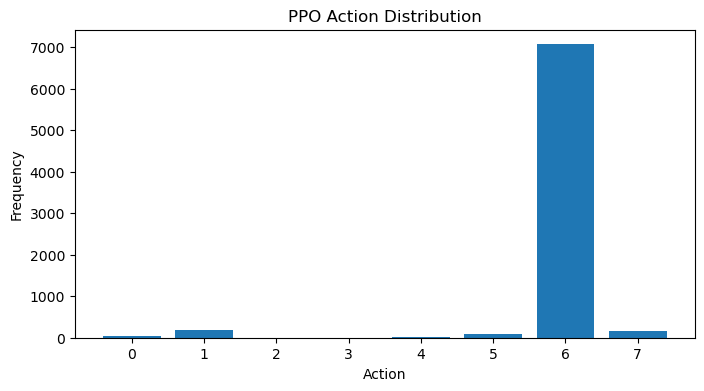

Plotting distribution for: ..\..\..\results\methods\Hyperparams_controller\ppo_logs\R203_100_10.json


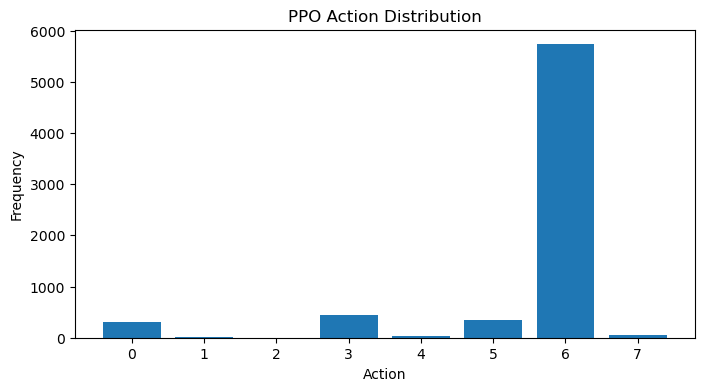

Plotting distribution for: ..\..\..\results\methods\Hyperparams_controller\ppo_logs\R203_50_5.json


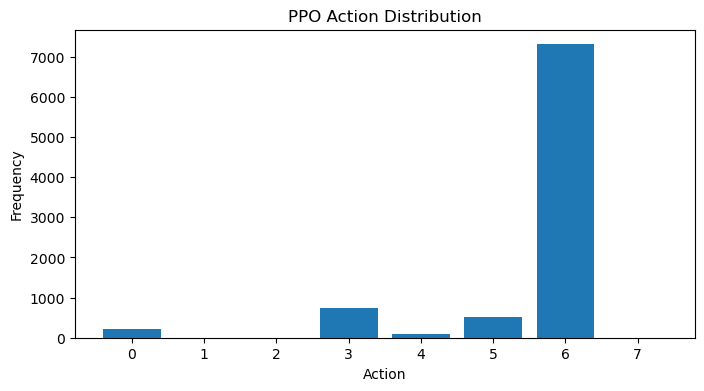

Plotting distribution for: ..\..\..\results\methods\Hyperparams_controller\ppo_logs\R207_100_10.json


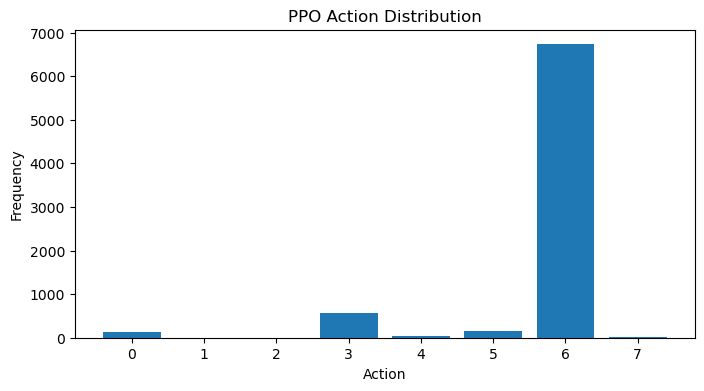

Plotting distribution for: ..\..\..\results\methods\Hyperparams_controller\ppo_logs\R209_50_5.json


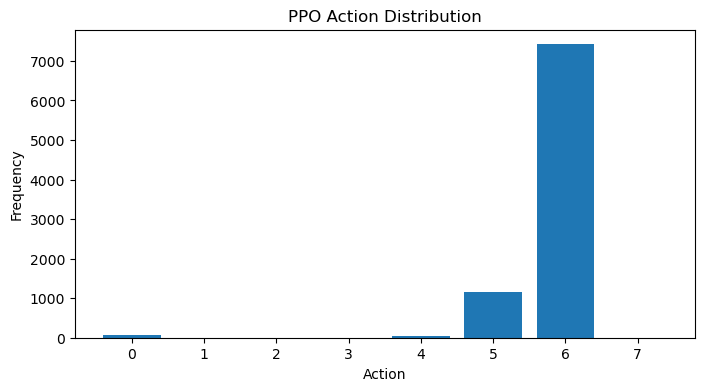

Plotting distribution for: ..\..\..\results\methods\Hyperparams_controller\ppo_logs\R210_100_10.json


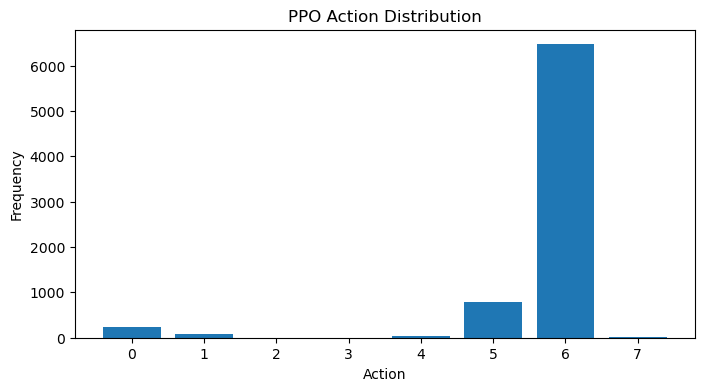

Plotting distribution for: ..\..\..\results\methods\Hyperparams_controller\ppo_logs\R211_50_5.json


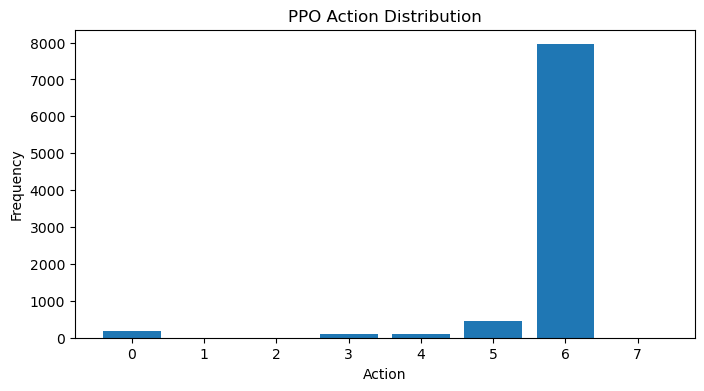

Plotting distribution for: ..\..\..\results\methods\Hyperparams_controller\ppo_logs\RC101_100_10.json


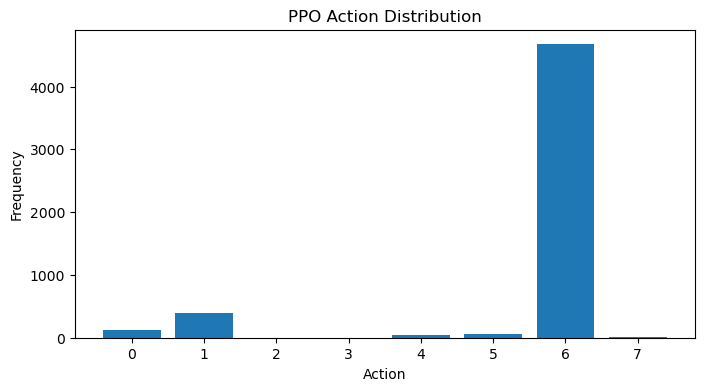

Plotting distribution for: ..\..\..\results\methods\Hyperparams_controller\ppo_logs\RC103_50_5.json


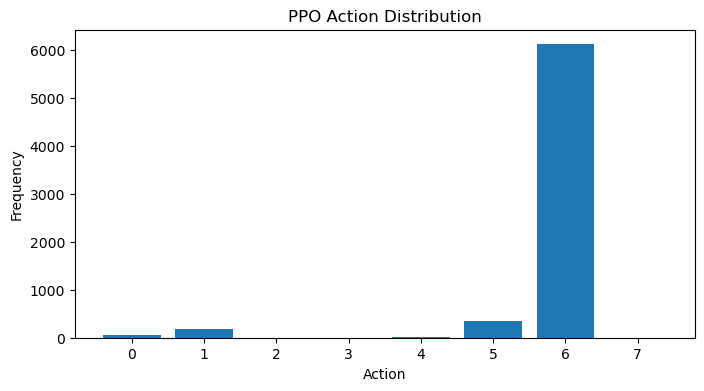

Plotting distribution for: ..\..\..\results\methods\Hyperparams_controller\ppo_logs\RC104_100_10.json


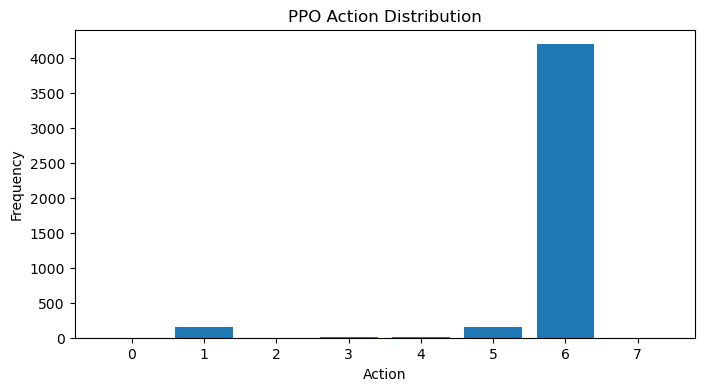

Plotting distribution for: ..\..\..\results\methods\Hyperparams_controller\ppo_logs\RC104_50_5.json


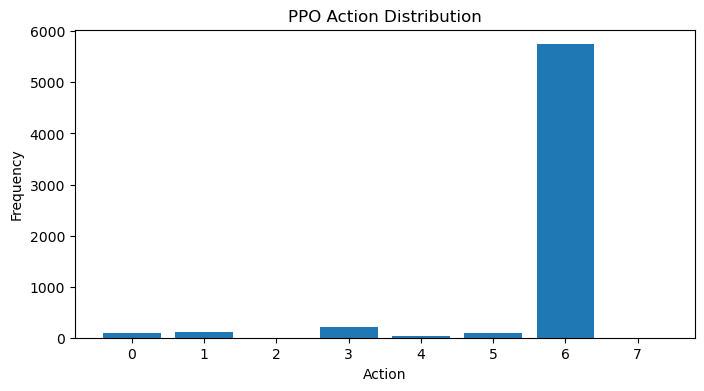

Plotting distribution for: ..\..\..\results\methods\Hyperparams_controller\ppo_logs\RC106_100_10.json


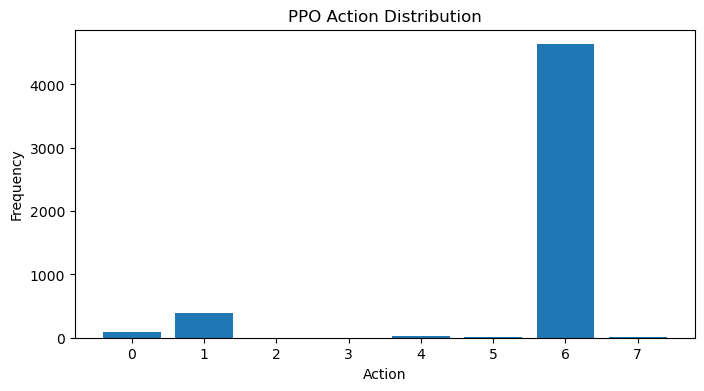

Plotting distribution for: ..\..\..\results\methods\Hyperparams_controller\ppo_logs\RC108_50_5.json


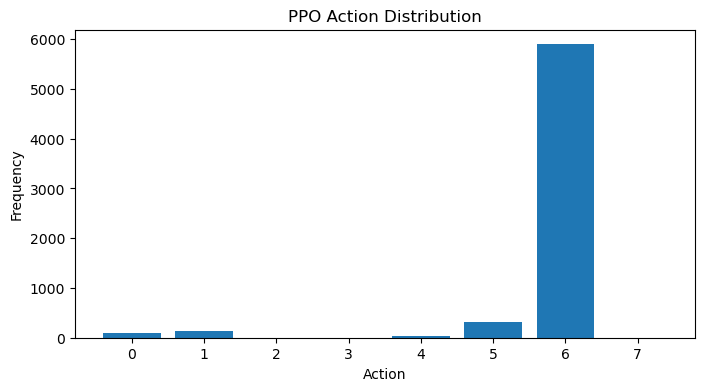

Plotting distribution for: ..\..\..\results\methods\Hyperparams_controller\ppo_logs\RC202_100_10.json


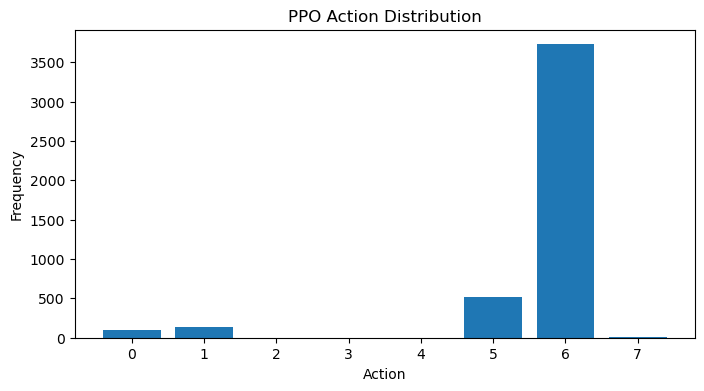

Plotting distribution for: ..\..\..\results\methods\Hyperparams_controller\ppo_logs\RC202_50_5.json


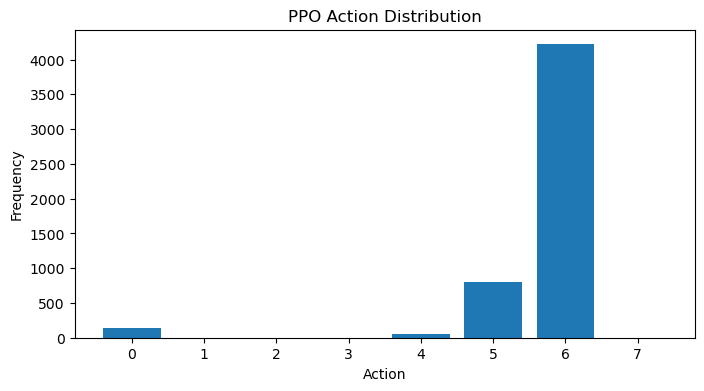

Plotting distribution for: ..\..\..\results\methods\Hyperparams_controller\ppo_logs\RC203_100_10.json


KeyboardInterrupt: 

In [13]:
files = get_ppo_log_files()
print(f"Found {len(files)} JSON files: {files}")
for log_path in files:
    print(f"Plotting distribution for: {log_path}")
    plot_action_distribution(log_path)

# Action vs improvement

In [15]:
def plot_action_success(log_path):
    with open(log_path, "r") as f:
        logs = json.load(f)

    success = {i: [] for i in range(8)}

    for x in logs:
        if "improved" in x:
            success[x["action"]].append(1 if x["improved"] else 0)

    rates = []
    for i in range(8):
        if len(success[i]) > 0:
            rates.append(np.mean(success[i]))
        else:
            rates.append(0)

    plt.figure(figsize=(8, 4))
    plt.bar(range(8), rates)
    plt.xlabel("Action")
    plt.ylabel("Success rate")
    plt.title("Action Success Rate")
    plt.show()

Found 36 JSON files: ['..\\..\\..\\results\\methods\\Hyperparams_controller\\ppo_logs\\C102_50_5.json', '..\\..\\..\\results\\methods\\Hyperparams_controller\\ppo_logs\\C103_100_10.json', '..\\..\\..\\results\\methods\\Hyperparams_controller\\ppo_logs\\C104_100_10.json', '..\\..\\..\\results\\methods\\Hyperparams_controller\\ppo_logs\\C105_50_5.json', '..\\..\\..\\results\\methods\\Hyperparams_controller\\ppo_logs\\C107_100_10.json', '..\\..\\..\\results\\methods\\Hyperparams_controller\\ppo_logs\\C109_50_5.json', '..\\..\\..\\results\\methods\\Hyperparams_controller\\ppo_logs\\C201_50_5.json', '..\\..\\..\\results\\methods\\Hyperparams_controller\\ppo_logs\\C202_100_10.json', '..\\..\\..\\results\\methods\\Hyperparams_controller\\ppo_logs\\C204_50_5.json', '..\\..\\..\\results\\methods\\Hyperparams_controller\\ppo_logs\\C206_100_10.json', '..\\..\\..\\results\\methods\\Hyperparams_controller\\ppo_logs\\C207_50_5.json', '..\\..\\..\\results\\methods\\Hyperparams_controller\\ppo_logs\\C

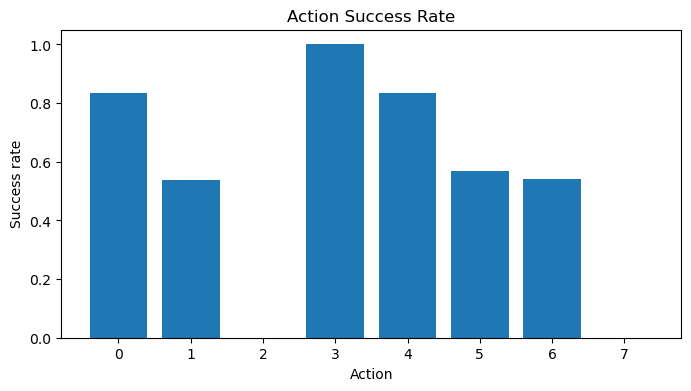

Plotting success rate for: ..\..\..\results\methods\Hyperparams_controller\ppo_logs\C103_100_10.json


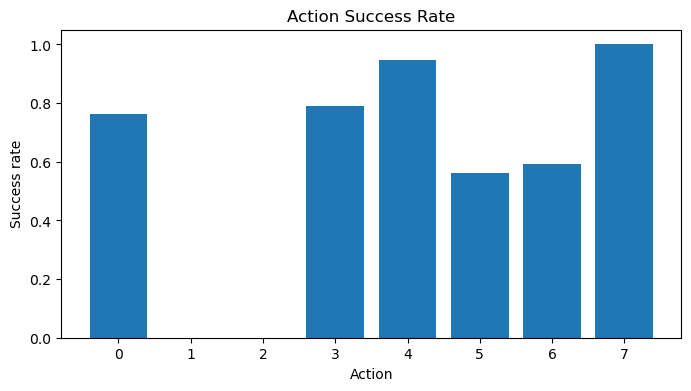

Plotting success rate for: ..\..\..\results\methods\Hyperparams_controller\ppo_logs\C104_100_10.json


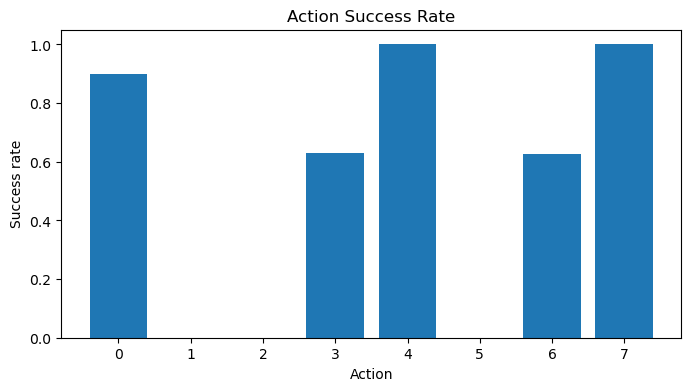

Plotting success rate for: ..\..\..\results\methods\Hyperparams_controller\ppo_logs\C105_50_5.json


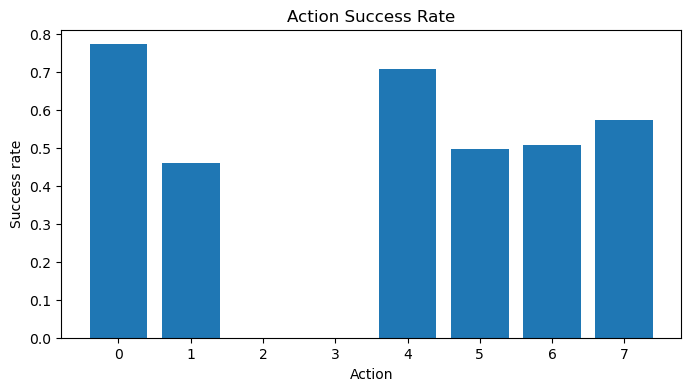

Plotting success rate for: ..\..\..\results\methods\Hyperparams_controller\ppo_logs\C107_100_10.json


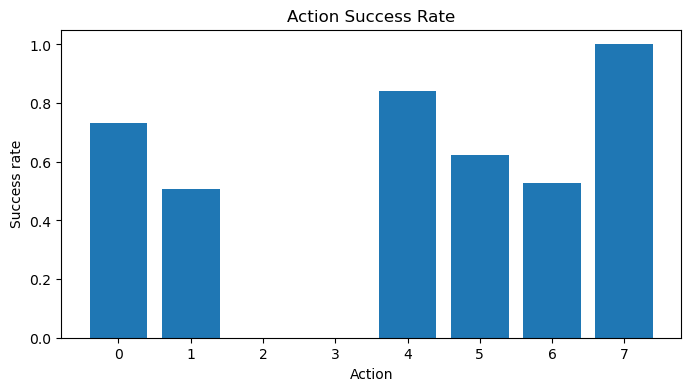

Plotting success rate for: ..\..\..\results\methods\Hyperparams_controller\ppo_logs\C109_50_5.json


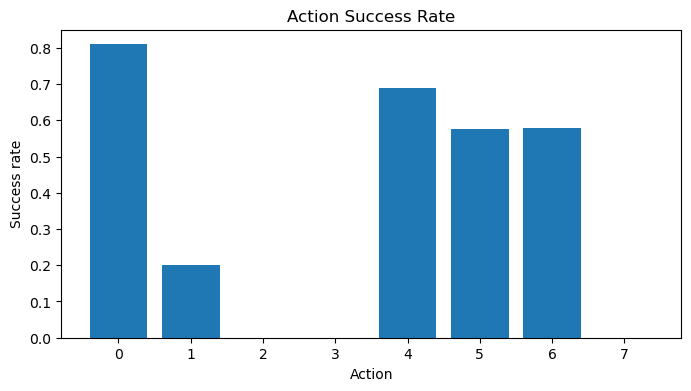

Plotting success rate for: ..\..\..\results\methods\Hyperparams_controller\ppo_logs\C201_50_5.json


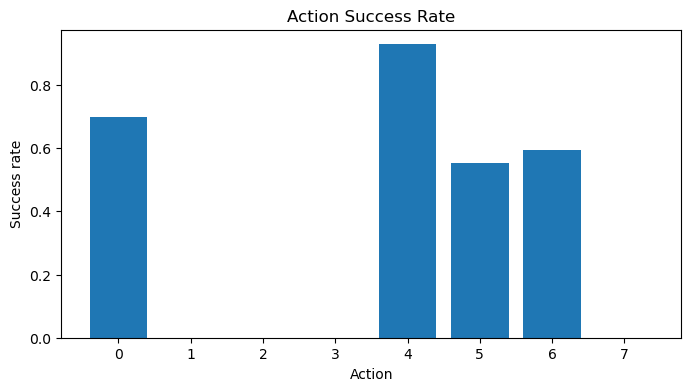

Plotting success rate for: ..\..\..\results\methods\Hyperparams_controller\ppo_logs\C202_100_10.json


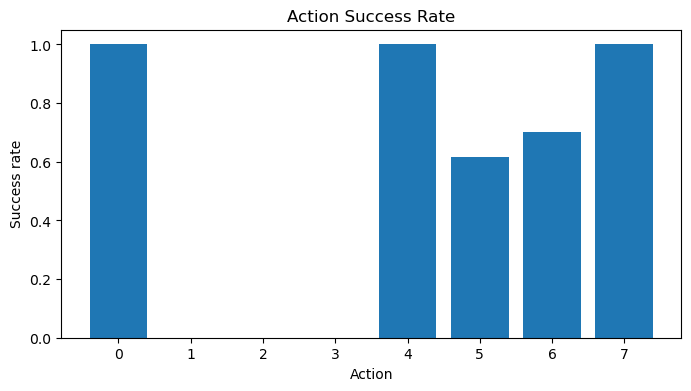

Plotting success rate for: ..\..\..\results\methods\Hyperparams_controller\ppo_logs\C204_50_5.json


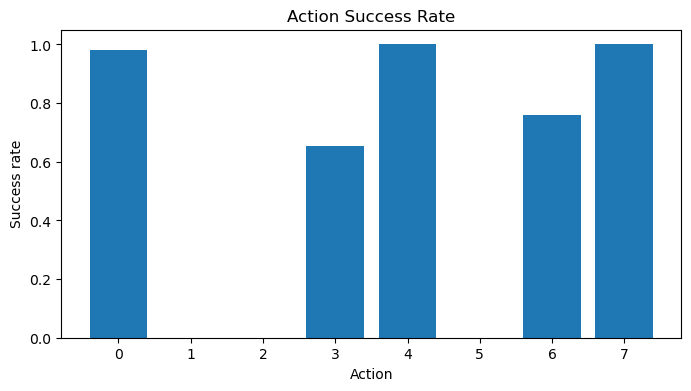

Plotting success rate for: ..\..\..\results\methods\Hyperparams_controller\ppo_logs\C206_100_10.json


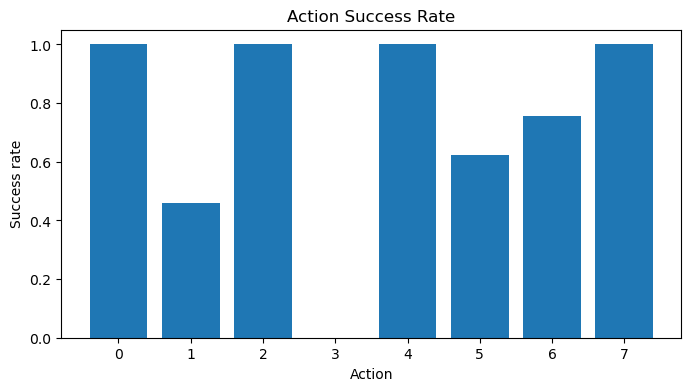

Plotting success rate for: ..\..\..\results\methods\Hyperparams_controller\ppo_logs\C207_50_5.json


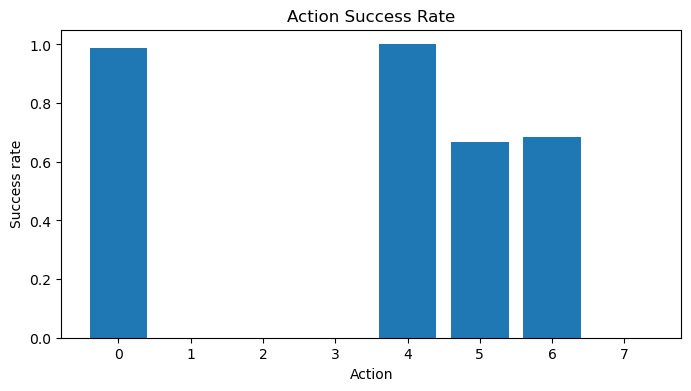

Plotting success rate for: ..\..\..\results\methods\Hyperparams_controller\ppo_logs\C208_100_10.json


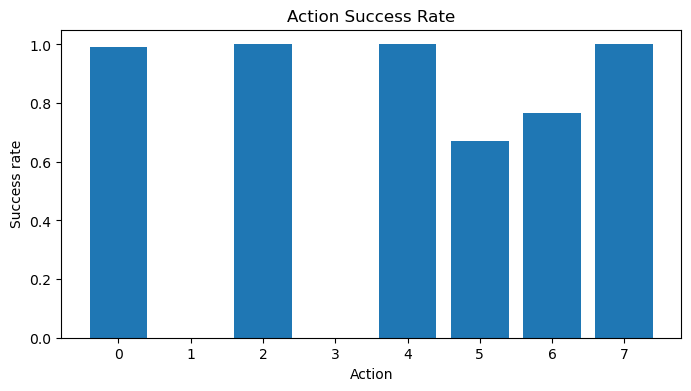

Plotting success rate for: ..\..\..\results\methods\Hyperparams_controller\ppo_logs\R101_100_10.json


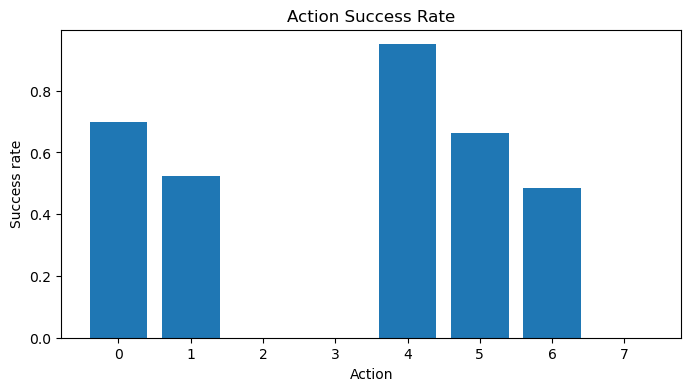

Plotting success rate for: ..\..\..\results\methods\Hyperparams_controller\ppo_logs\R102_50_5.json


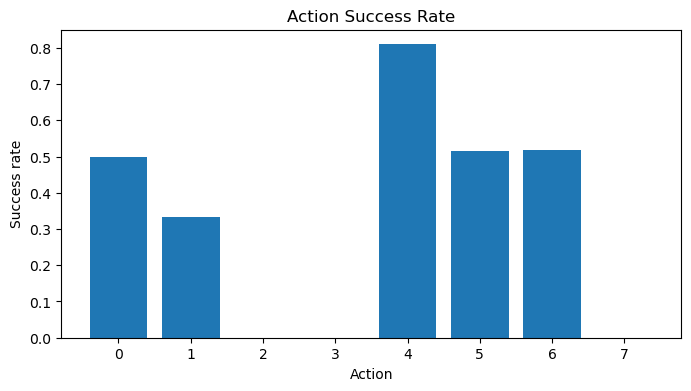

Plotting success rate for: ..\..\..\results\methods\Hyperparams_controller\ppo_logs\R105_100_10.json


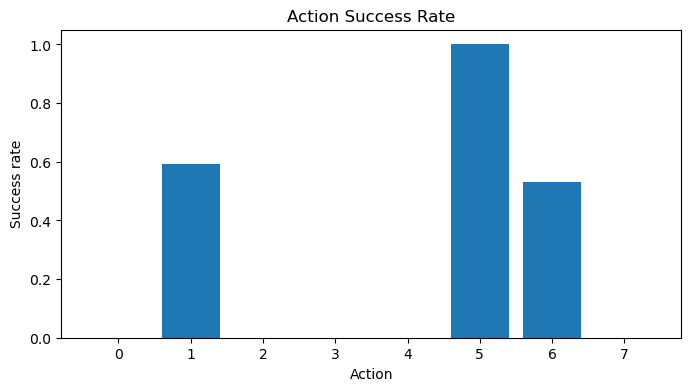

Plotting success rate for: ..\..\..\results\methods\Hyperparams_controller\ppo_logs\R106_50_5.json


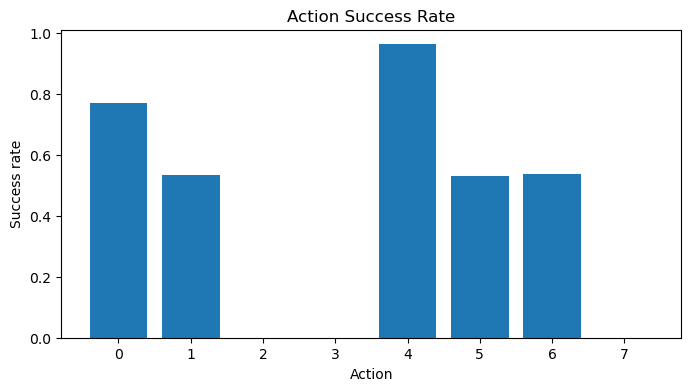

Plotting success rate for: ..\..\..\results\methods\Hyperparams_controller\ppo_logs\R110_50_5.json


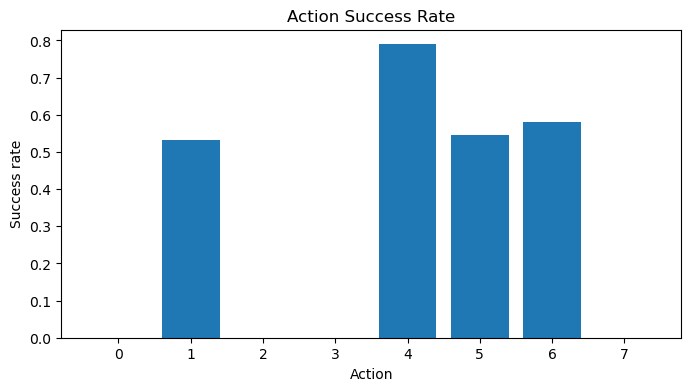

Plotting success rate for: ..\..\..\results\methods\Hyperparams_controller\ppo_logs\R111_100_10.json


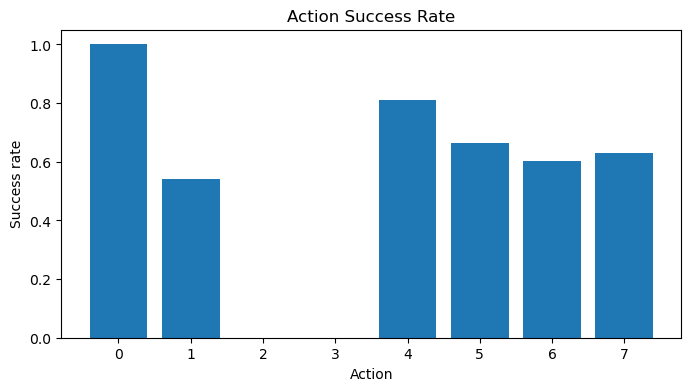

Plotting success rate for: ..\..\..\results\methods\Hyperparams_controller\ppo_logs\R203_100_10.json


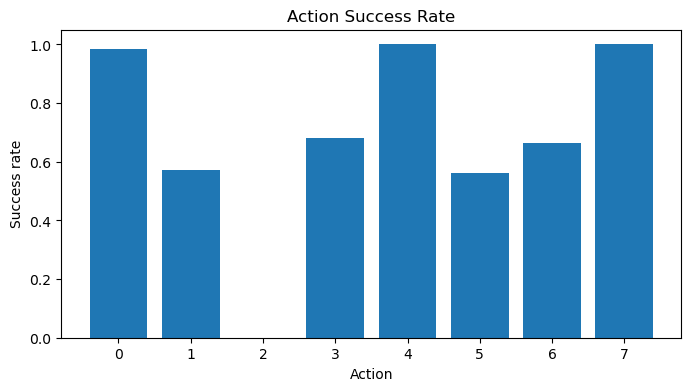

Plotting success rate for: ..\..\..\results\methods\Hyperparams_controller\ppo_logs\R203_50_5.json


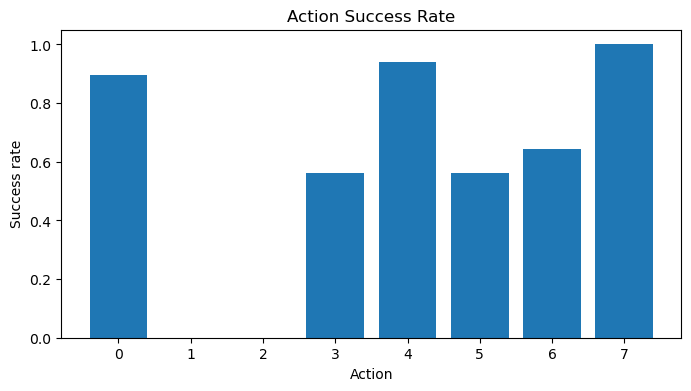

Plotting success rate for: ..\..\..\results\methods\Hyperparams_controller\ppo_logs\R207_100_10.json


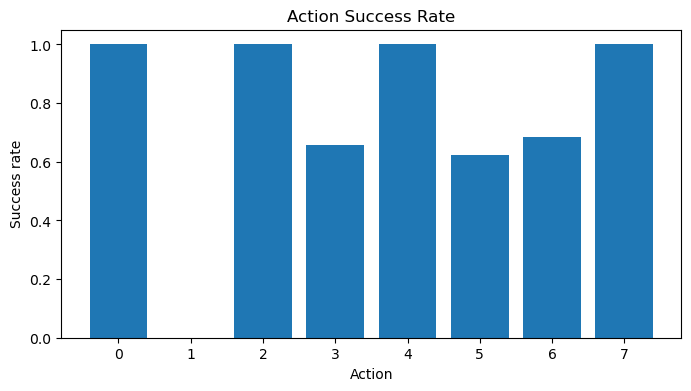

Plotting success rate for: ..\..\..\results\methods\Hyperparams_controller\ppo_logs\R209_50_5.json


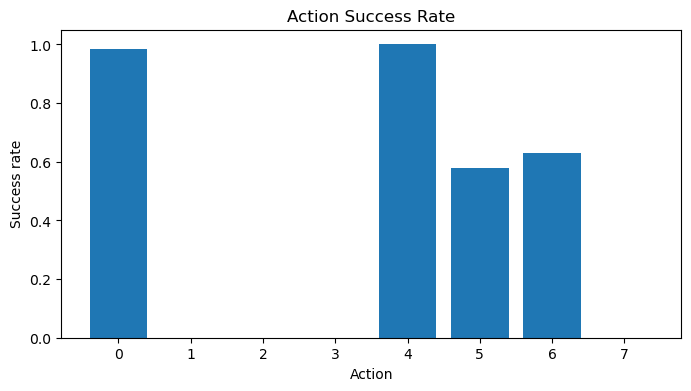

Plotting success rate for: ..\..\..\results\methods\Hyperparams_controller\ppo_logs\R210_100_10.json


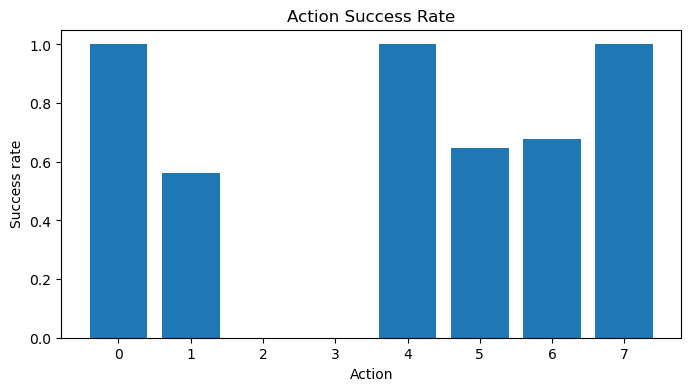

Plotting success rate for: ..\..\..\results\methods\Hyperparams_controller\ppo_logs\R211_50_5.json


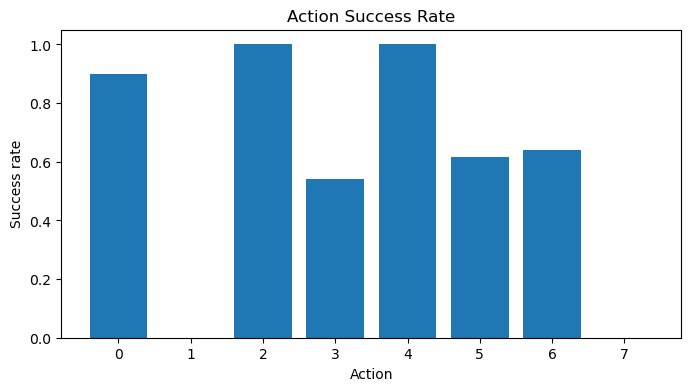

Plotting success rate for: ..\..\..\results\methods\Hyperparams_controller\ppo_logs\RC101_100_10.json


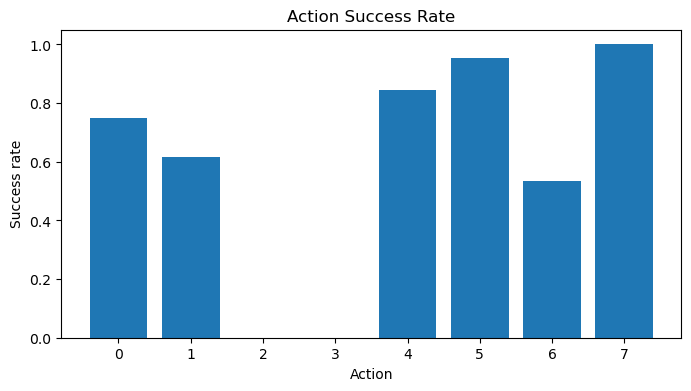

Plotting success rate for: ..\..\..\results\methods\Hyperparams_controller\ppo_logs\RC103_50_5.json


KeyboardInterrupt: 

In [16]:
files = get_ppo_log_files()
print(f"Found {len(files)} JSON files: {files}")
for log_path in files:
    print(f"Plotting success rate for: {log_path}")
    plot_action_success(log_path)


# Action vs improvement magnitude

In [ ]:
def plot_action_gain(log_path):
    with open(log_path, "r") as f:
        logs = json.load(f)

    gains = {i: [] for i in range(8)}

    for x in logs:
        if "F_before" in x and "F_after" in x:
            gain = x["F_before"] - x["F_after"]
            gains[x["action"]].append(gain)

    avg_gains = [
        np.mean(gains[i]) if len(gains[i]) > 0 else 0
        for i in range(8)
    ]

    plt.figure(figsize=(8, 4))
    plt.bar(range(8), avg_gains)
    plt.xlabel("Action")
    plt.ylabel("Average improvement")
    plt.title("Action Effectiveness")
    plt.show()

In [ ]:
files = get_ppo_log_files()
print(f"Found {len(files)} JSON files: {files}")
for log_path in files:
    print(f"Plotting gain for: {log_path}")
    plot_action_gain(log_path)

# Action over time

In [17]:
def plot_actions_over_time(log_path):
    with open(log_path, "r") as f:
        logs = json.load(f)

    actions = [x["action"] for x in logs]

    plt.figure(figsize=(12, 4))
    plt.plot(actions, alpha=0.7)
    plt.xlabel("Step")
    plt.ylabel("Action")
    plt.title("Action sequence over time")
    plt.show()

Found 36 JSON files: ['..\\..\\..\\results\\methods\\Hyperparams_controller\\ppo_logs\\C102_50_5.json', '..\\..\\..\\results\\methods\\Hyperparams_controller\\ppo_logs\\C103_100_10.json', '..\\..\\..\\results\\methods\\Hyperparams_controller\\ppo_logs\\C104_100_10.json', '..\\..\\..\\results\\methods\\Hyperparams_controller\\ppo_logs\\C105_50_5.json', '..\\..\\..\\results\\methods\\Hyperparams_controller\\ppo_logs\\C107_100_10.json', '..\\..\\..\\results\\methods\\Hyperparams_controller\\ppo_logs\\C109_50_5.json', '..\\..\\..\\results\\methods\\Hyperparams_controller\\ppo_logs\\C201_50_5.json', '..\\..\\..\\results\\methods\\Hyperparams_controller\\ppo_logs\\C202_100_10.json', '..\\..\\..\\results\\methods\\Hyperparams_controller\\ppo_logs\\C204_50_5.json', '..\\..\\..\\results\\methods\\Hyperparams_controller\\ppo_logs\\C206_100_10.json', '..\\..\\..\\results\\methods\\Hyperparams_controller\\ppo_logs\\C207_50_5.json', '..\\..\\..\\results\\methods\\Hyperparams_controller\\ppo_logs\\C

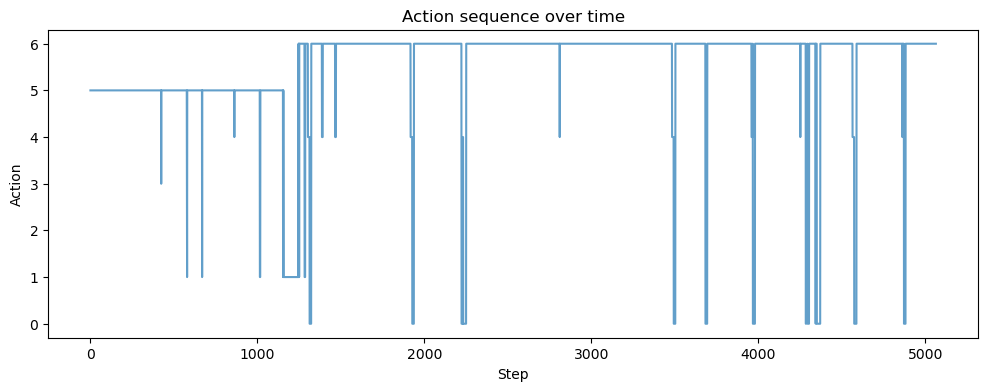

Plotting actions over time for: ..\..\..\results\methods\Hyperparams_controller\ppo_logs\C103_100_10.json


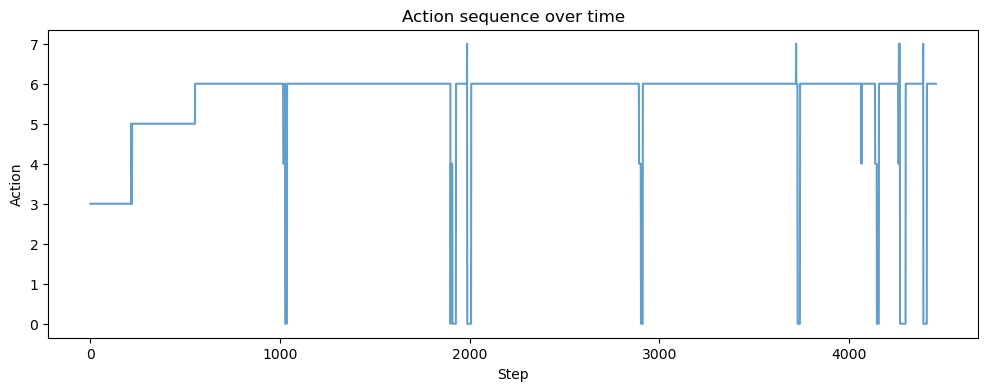

Plotting actions over time for: ..\..\..\results\methods\Hyperparams_controller\ppo_logs\C104_100_10.json


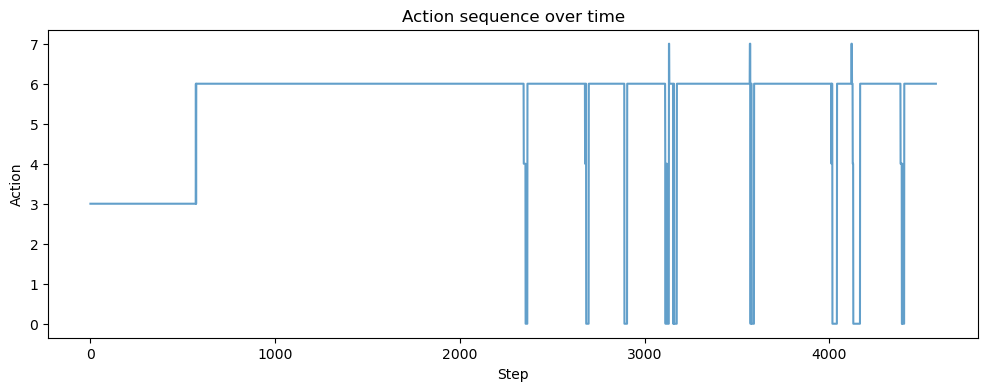

Plotting actions over time for: ..\..\..\results\methods\Hyperparams_controller\ppo_logs\C105_50_5.json


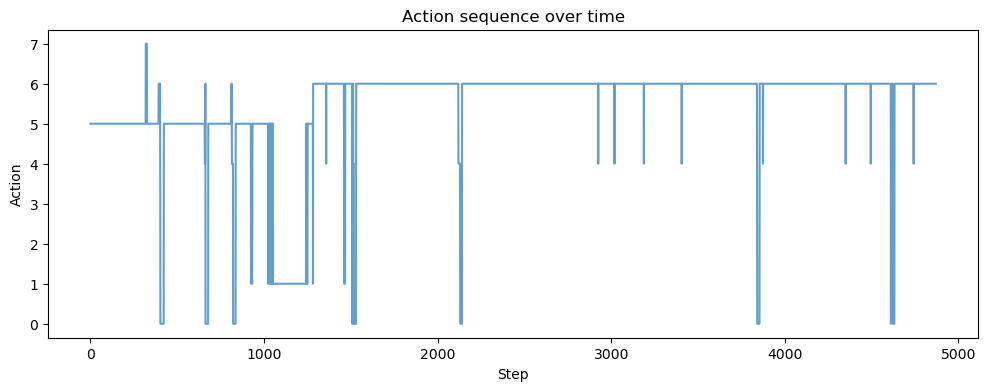

Plotting actions over time for: ..\..\..\results\methods\Hyperparams_controller\ppo_logs\C107_100_10.json


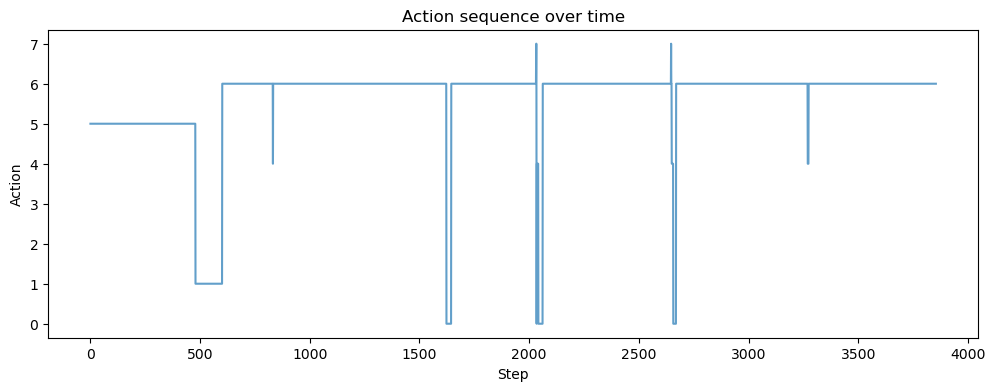

Plotting actions over time for: ..\..\..\results\methods\Hyperparams_controller\ppo_logs\C109_50_5.json


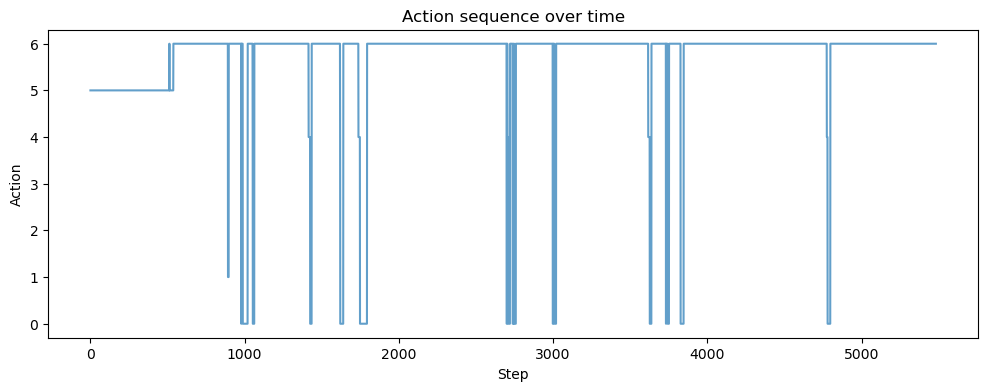

Plotting actions over time for: ..\..\..\results\methods\Hyperparams_controller\ppo_logs\C201_50_5.json


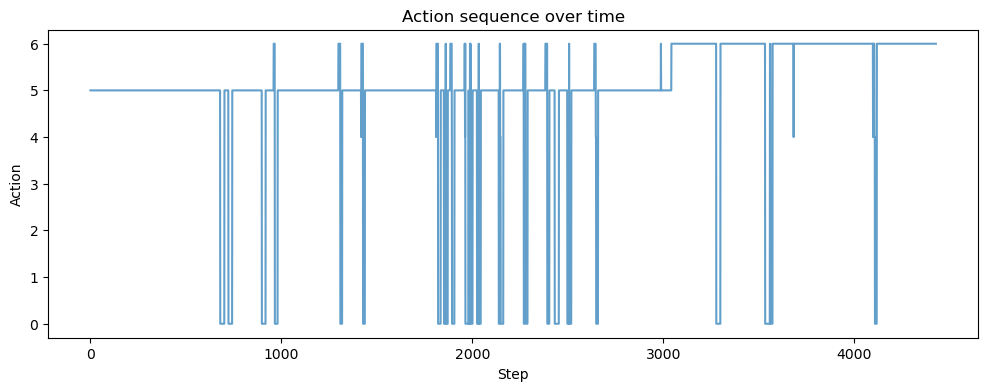

Plotting actions over time for: ..\..\..\results\methods\Hyperparams_controller\ppo_logs\C202_100_10.json


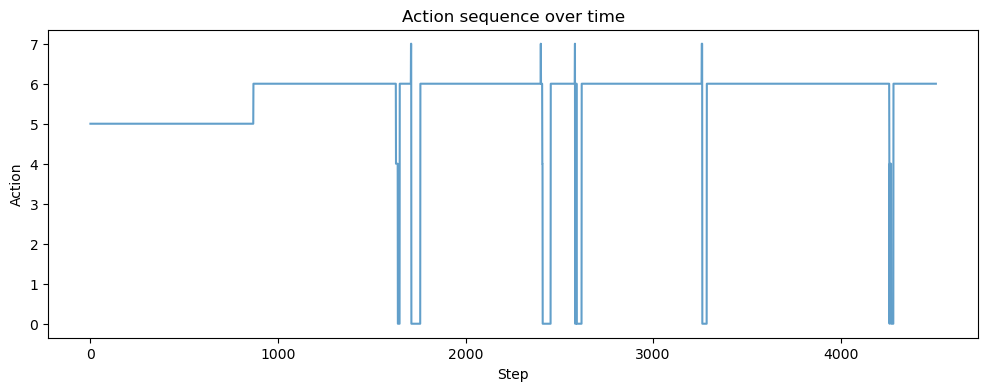

Plotting actions over time for: ..\..\..\results\methods\Hyperparams_controller\ppo_logs\C204_50_5.json


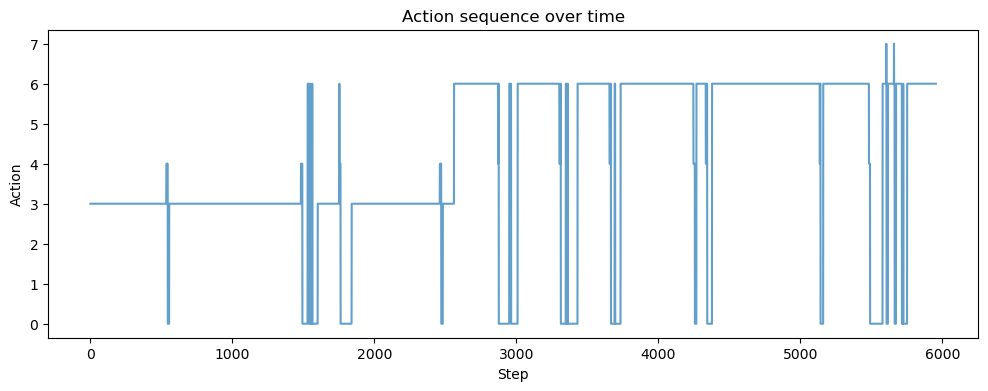

Plotting actions over time for: ..\..\..\results\methods\Hyperparams_controller\ppo_logs\C206_100_10.json


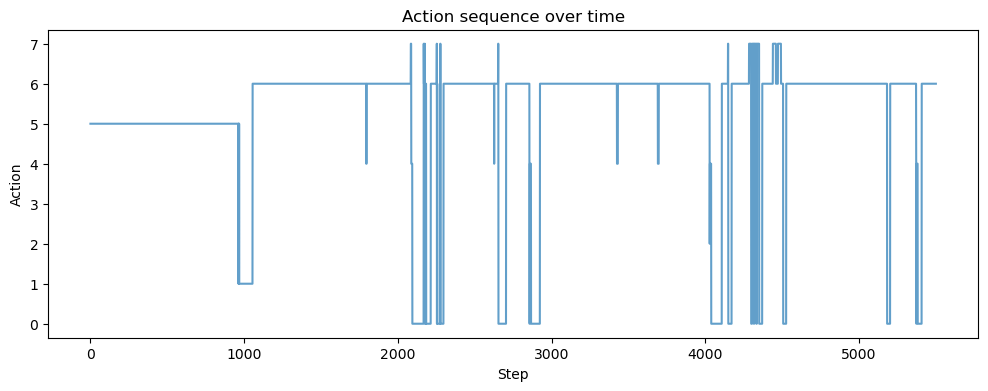

Plotting actions over time for: ..\..\..\results\methods\Hyperparams_controller\ppo_logs\C207_50_5.json


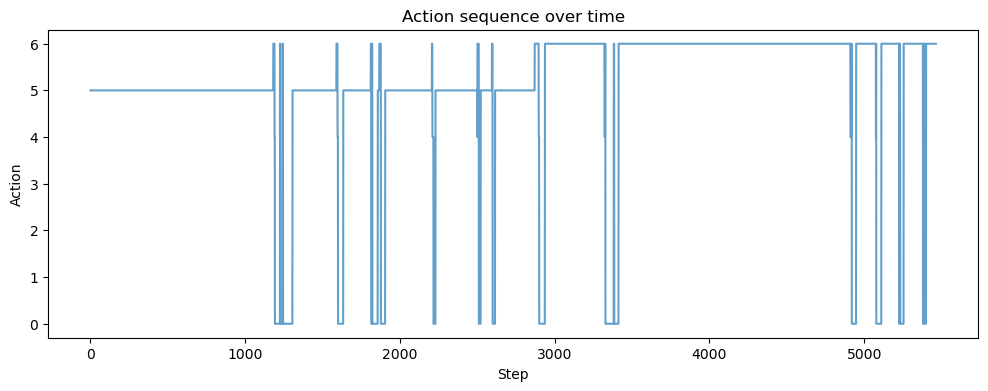

Plotting actions over time for: ..\..\..\results\methods\Hyperparams_controller\ppo_logs\C208_100_10.json


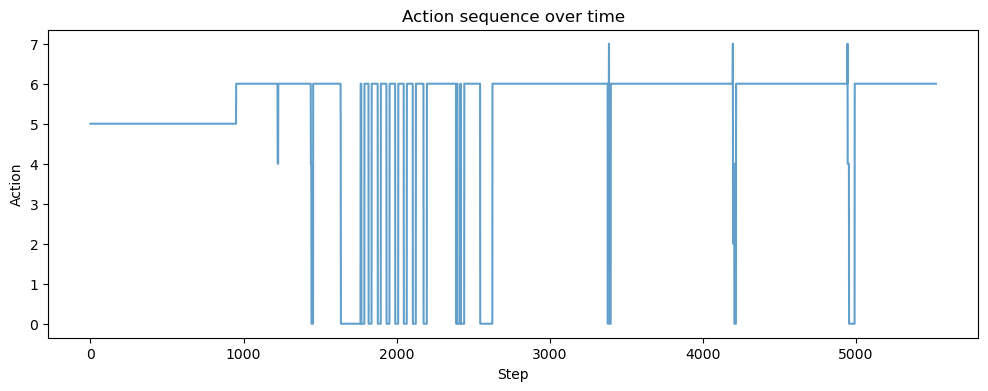

Plotting actions over time for: ..\..\..\results\methods\Hyperparams_controller\ppo_logs\R101_100_10.json


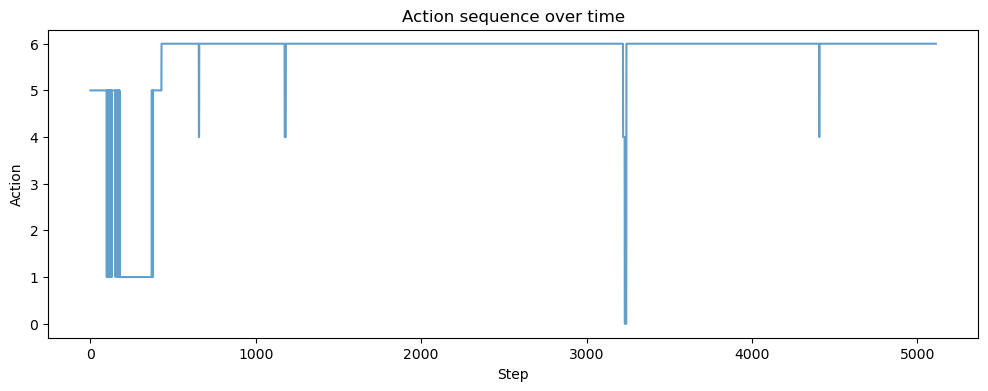

Plotting actions over time for: ..\..\..\results\methods\Hyperparams_controller\ppo_logs\R102_50_5.json


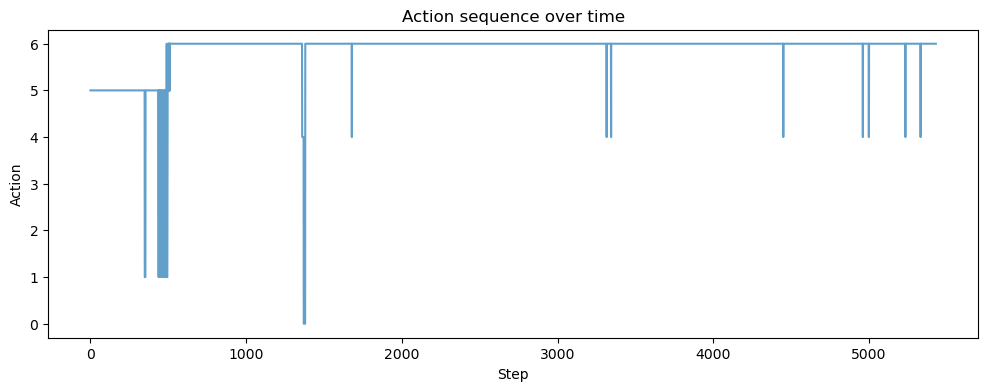

Plotting actions over time for: ..\..\..\results\methods\Hyperparams_controller\ppo_logs\R105_100_10.json


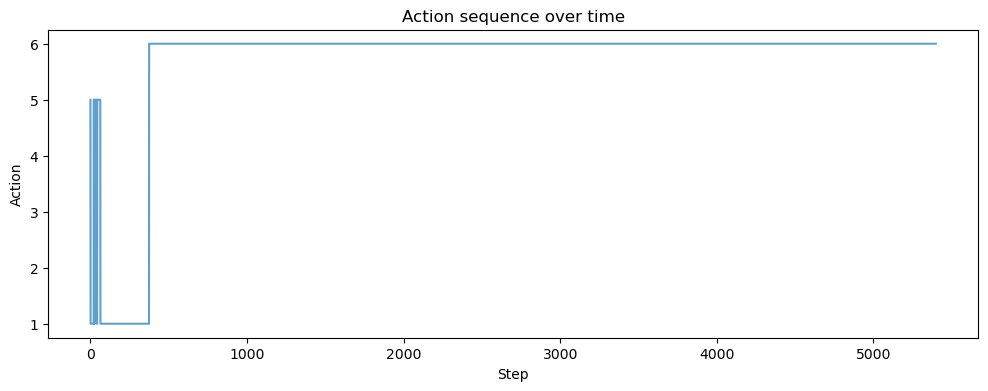

Plotting actions over time for: ..\..\..\results\methods\Hyperparams_controller\ppo_logs\R106_50_5.json


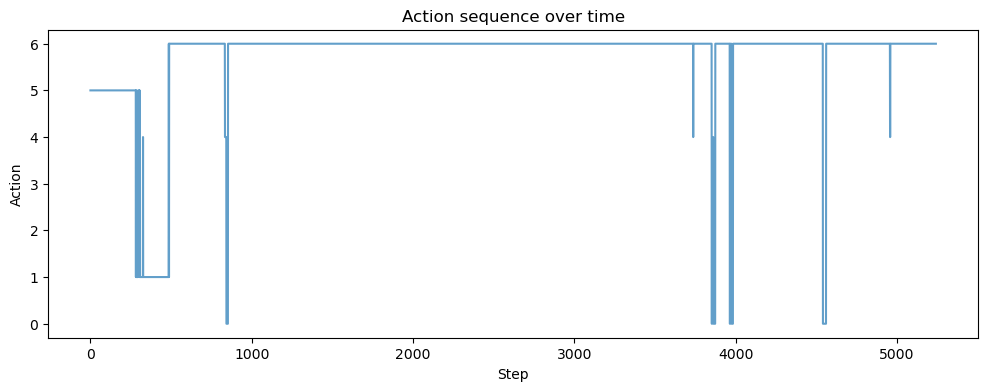

Plotting actions over time for: ..\..\..\results\methods\Hyperparams_controller\ppo_logs\R110_50_5.json


KeyboardInterrupt: 

In [18]:
files = get_ppo_log_files()
print(f"Found {len(files)} JSON files: {files}")
for log_path in files:
    print(f"Plotting actions over time for: {log_path}")
    plot_actions_over_time(log_path)